# 🎓 Identificación Temprana de Deserción y Éxito Académico con Apache Spark ML

**Autor:** Juan David Ortiz Pérez  
**Asignatura:** Big Data — Parcial Práctico (Spark ML + Despliegue Web en Streamlit)  
**Conjunto de datos:** *Predict Students' Dropout and Academic Success* (UCI / Kaggle, ~4.424 estudiantes, 37 variables, separador `;`)

---

## Estructura del Notebook
Este cuaderno está organizado en tres secciones principales siguiendo los lineamientos metodológicos de ciencia de datos a gran escala con **PySpark ML**:
- **Sección A:** Carga, limpieza, ingeniería de características y partición (Tareas 1 a 3).
- **Sección B:** Pipelines, hiperparametrización y validación cruzada (Tareas 4 y 5).
- **Sección C:** Evaluación sobre el conjunto de prueba, selección y guardado del mejor modelo en `modelo_final` y `modelo_final.zip` (Tarea 6).

---
# Sección A. Carga, limpieza, ingeniería de características y partición (Tareas 1 a 3)

## Tarea 1: Carga y exploración de datos
### 1.1 Configuración del entorno e inicialización de `SparkSession`
En la siguiente celda configuramos las variables de entorno necesarias para que el motor de Apache Spark se comunique de manera estable con el intérprete de Python (`PYSPARK_PYTHON`) y el sistema de archivos local, y creamos la sesión `SparkSession` llamada `dropout_sparkml`.  
Se asignan **4 GB de memoria al driver** (`spark.driver.memory = 4g`), se desactiva la propagación de restricciones del optimizador Catalyst (`spark.sql.constraintPropagation.enabled = false`) para evitar explosión del plan lógico en pipelines con múltiples transformadores, y se limita el paralelismo por defecto a **máximo 4 particiones** dado el tamaño compacto del dataset (~4.400 registros).

In [1]:
import os
import sys
import re
import json
import shutil
import zipfile
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración automática para ejecución compatible en Google Colab, Linux y Windows
if os.name == "nt":
    hadoop_home = os.environ.get("HADOOP_HOME", os.path.join(os.path.expanduser("~"), ".hadoop"))
    os.makedirs(os.path.join(hadoop_home, "bin"), exist_ok=True)
    for fn in ("winutils.exe", "hadoop.dll"):
        target = os.path.join(hadoop_home, "bin", fn)
        if not os.path.exists(target):
            urllib.request.urlretrieve(
                f"https://raw.githubusercontent.com/cdarlint/winutils/master/hadoop-3.3.5/bin/{fn}",
                target,
            )
    os.environ["HADOOP_HOME"] = hadoop_home
    if os.path.join(hadoop_home, "bin") not in os.environ.get("PATH", ""):
        os.environ["PATH"] = os.path.join(hadoop_home, "bin") + os.pathsep + os.environ.get("PATH", "")

os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import NumericType

spark = (
    SparkSession.builder
    .appName("dropout_sparkml")
    .master("local[2]")
    .config("spark.driver.host", "127.0.0.1")
    .config("spark.driver.bindAddress", "127.0.0.1")
    .config("spark.driver.memory", "4g")
    .config("spark.sql.constraintPropagation.enabled", "false")  # evita la explosión del optimizador
    .config("spark.sql.shuffle.partitions", "4")
    .config("spark.default.parallelism", "4")
    .config("spark.ui.enabled", "false")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("WARN")
print("Versión de Apache Spark:", spark.version)
print("Memoria del Driver configurada:", spark.conf.get("spark.driver.memory"))
print("Particiones de shuffle:", spark.conf.get("spark.sql.shuffle.partitions"))

Versión de Apache Spark: 3.5.9


Memoria del Driver configurada: 4g
Particiones de shuffle: 4


### 1.2 Carga del archivo CSV y exploración inicial del esquema y dimensiones
En la siguiente celda cargamos el dataset `data.csv` (descargado del repositorio oficial *Predict Students' Dropout and Academic Success*) indicando `header=True`, detección automática de tipos `inferSchema=True` y el separador punto y coma `sep=";"`. Además, aplicamos `.coalesce(2)` para mantener un número reducido de particiones (máximo 4) y mostramos las dimensiones (filas y columnas) junto con el esquema inferido por Spark.

In [2]:
if not os.path.exists("data.csv"):
    print("Descargando data.csv desde el repositorio oficial UCI...")
    zip_url = "https://archive.ics.uci.edu/static/public/697/predict+students+dropout+and+academic+success.zip"
    urllib.request.urlretrieve(zip_url, "dataset_uci.zip")
    with zipfile.ZipFile("dataset_uci.zip", "r") as zf:
        zf.extract("data.csv", ".")

df = spark.read.csv("data.csv", header=True, inferSchema=True, sep=";").coalesce(2)

num_rows = df.count()
num_cols = len(df.columns)
print(f"Número total de filas (estudiantes): {num_rows}")
print(f"Número total de columnas: {num_cols}")
print(f"Número de particiones del DataFrame: {df.rdd.getNumPartitions()}\n")
print("Esquema inferido del DataFrame:")
df.printSchema()

Número total de filas (estudiantes): 4424
Número total de columnas: 37
Número de particiones del DataFrame: 1

Esquema inferido del DataFrame:
root
 |-- Marital status: integer (nullable = true)
 |-- Application mode: integer (nullable = true)
 |-- Application order: integer (nullable = true)
 |-- Course: integer (nullable = true)
 |-- Daytime/evening attendance\t: integer (nullable = true)
 |-- Previous qualification: integer (nullable = true)
 |-- Previous qualification (grade): double (nullable = true)
 |-- Nacionality: integer (nullable = true)
 |-- Mother's qualification: integer (nullable = true)
 |-- Father's qualification: integer (nullable = true)
 |-- Mother's occupation: integer (nullable = true)
 |-- Father's occupation: integer (nullable = true)
 |-- Admission grade: double (nullable = true)
 |-- Displaced: integer (nullable = true)
 |-- Educational special needs: integer (nullable = true)
 |-- Debtor: integer (nullable = true)
 |-- Tuition fees up to date: integer (nullab

### 1.3 Distribución de la variable objetivo (`Target`)
En la siguiente celda calculamos el conteo absoluto y el porcentaje que representa cada una de las tres clases de la variable objetivo `Target` (`Graduate`, `Dropout` y `Enrolled`), y generamos un gráfico de barras para visualizar claramente el desbalance entre las categorías.

Distribución de clases en la variable objetivo (Target):


+--------+-----+----------+
|Target  |count|porcentaje|
+--------+-----+----------+
|Graduate|2209 |49.93     |
|Dropout |1421 |32.12     |
|Enrolled|794  |17.95     |
+--------+-----+----------+



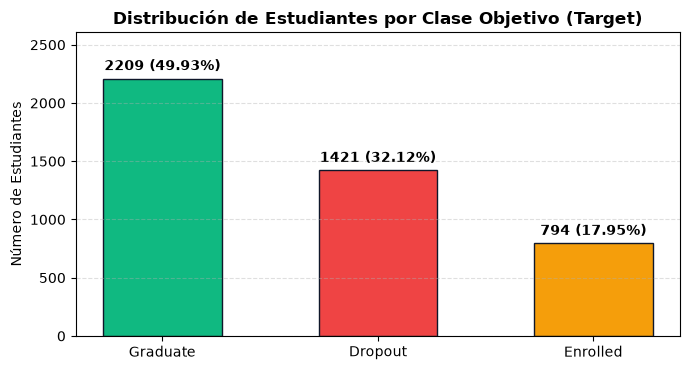

In [3]:
target_dist = (
    df.groupBy("Target")
    .count()
    .withColumn("porcentaje", F.round((F.col("count") / num_rows) * 100, 2))
    .orderBy(F.col("count").desc())
)
print("Distribución de clases en la variable objetivo (Target):")
target_dist.show(truncate=False)

dist_pdf = target_dist.toPandas()
fig, ax = plt.subplots(figsize=(7, 3.8))
colors = ["#10B981", "#EF4444", "#F59E0B"]
bars = ax.bar(dist_pdf["Target"], dist_pdf["count"], color=colors, edgecolor="#0F172A", width=0.55)
ax.set_title("Distribución de Estudiantes por Clase Objetivo (Target)", fontsize=12, fontweight="bold")
ax.set_ylabel("Número de Estudiantes")
ax.set_ylim(0, max(dist_pdf["count"]) * 1.18)
ax.grid(axis="y", linestyle="--", alpha=0.4)
for bar, row in zip(bars, dist_pdf.itertuples()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 45,
        f"{row.count} ({row.porcentaje}%)",
        ha="center",
        va="bottom",
        fontweight="bold",
        fontsize=10,
    )
plt.tight_layout()
plt.show()

### 1.4 Análisis del desbalance de clases
A partir de la distribución obtenida sobre los **4.424 estudiantes** del conjunto de datos:
1. **Clase dominante (`Graduate`):** Cuenta con **2.209 registros (49,93 %)**, es decir, prácticamente la mitad de toda la población estudiantil analizada corresponde a estudiantes que lograron graduarse.
2. **Clase intermedia (`Dropout`):** Cuenta con **1.421 registros (32,12 %)**, representando casi un tercio de estudiantes que desertaron prematuramente.
3. **Clase minoritaria (`Enrolled`):** Cuenta con apenas **794 registros (17,95 %)**, correspondiente a estudiantes que permanecen matriculados sin haberse graduado ni desertado al cierre de la ventana de observación (una proporción de **2,78 a 1** frente a la clase mayoritaria `Graduate`).

**¿Por qué importa este desbalance?**
- **Sesgo hacia la clase mayoritaria:** Si entrenamos clasificadores optimizando únicamente la exactitud global (*Accuracy*) sin tratar el desbalance, el algoritmo tenderá a sobre-predecir `Graduate` y tendrá una sensibilidad (*Recall*) muy baja en la clase minoritaria `Enrolled` y en casos frontera entre `Enrolled` y `Dropout`.
- **Impacto institucional crítico:** Para la universidad, el costo de un **falso negativo en `Dropout`** (un estudiante en riesgo real de deserción que el modelo clasifica erróneamente como `Graduate` o `Enrolled`) significa perder la oportunidad de intervenir a tiempo con tutorías, apoyo financiero o bienestar universitario. Del mismo modo, confundir a los estudiantes `Enrolled` impide focalizar correctamente los recursos de acompañamiento académico. Por ello es indispensable aplicar **ponderación por clase (`weightCol`)** durante el entrenamiento y utilizar el **F1-score ponderado** como criterio de validación cruzada y selección de modelo.

---
## Tarea 2: Preprocesamiento de datos
### 2.1 Normalización de nombres de columnas con expresiones regulares
Varios nombres de columnas originales contienen espacios, paréntesis, apóstrofes, barras e incluso tabulaciones al final (por ejemplo, `'Daytime/evening attendance\t'`, `"Mother's qualification"`, `'Curricular units 1st sem (grade)'`).  
En la siguiente celda utilizamos una expresión regular (`re.sub(r'[^a-z0-9]+', '_', col.strip().lower()).strip('_')`) para transformar todos los encabezados a minúsculas, sin espacios ni símbolos especiales, garantizando identificadores limpios y seguros en todo el pipeline de Spark ML.

In [4]:
def normalize_column_name(col_name: str) -> str:
    cleaned = re.sub(r"[^a-z0-9]+", "_", col_name.strip().lower())
    return re.sub(r"^_+|_+$", "", cleaned)

original_cols = df.columns
normalized_cols = [normalize_column_name(c) for c in original_cols]

print("Mapeo de nombres de columnas (Original -> Normalizado):")
for orig, norm in zip(original_cols, normalized_cols):
    print(f"  {orig!r:48} -> {norm}")

df = df.toDF(*normalized_cols)

Mapeo de nombres de columnas (Original -> Normalizado):
  'Marital status'                                 -> marital_status
  'Application mode'                               -> application_mode
  'Application order'                              -> application_order
  'Course'                                         -> course
  'Daytime/evening attendance\t'                   -> daytime_evening_attendance
  'Previous qualification'                         -> previous_qualification
  'Previous qualification (grade)'                 -> previous_qualification_grade
  'Nacionality'                                    -> nacionality
  "Mother's qualification"                         -> mother_s_qualification
  "Father's qualification"                         -> father_s_qualification
  "Mother's occupation"                            -> mother_s_occupation
  "Father's occupation"                            -> father_s_occupation
  'Admission grade'                                -> admissio

### 2.2 Revisión y eliminación de duplicados, valores nulos y verificación de tipos de dato
En la siguiente celda verificamos la calidad e integridad del dataset:
1. Contamos y eliminamos posibles filas duplicadas con `dropDuplicates()`.
2. Calculamos el conteo de valores nulos (`IS NULL`) o `NaN` en cada una de las 37 columnas y aplicamos `dropna()`.
3. Inspeccionamos los tipos de datos (`df.dtypes`) para confirmar que todas las variables predictoras sean numéricas (`int` o `double`) y la variable objetivo `target` sea de tipo texto (`string`).

In [5]:
rows_before = df.count()
df = df.dropDuplicates().coalesce(2)
rows_after_dedup = df.count()
print(f"Filas antes de eliminar duplicados: {rows_before}")
print(f"Filas después de dropDuplicates():  {rows_after_dedup} (Duplicados eliminados: {rows_before - rows_after_dedup})")

# Conteo de nulos o NaN por columna
null_exprs = [
    F.sum(
        F.when(
            F.col(c).isNull() | (F.isnan(F.col(c)) if isinstance(df.schema[c].dataType, NumericType) else F.lit(False)),
            1,
        ).otherwise(0)
    ).alias(c)
    for c in df.columns
]
null_counts_row = df.select(null_exprs).collect()[0].asDict()
total_nulls = sum(null_counts_row.values())
print(f"Total de valores nulos/NaN encontrados en las 37 columnas: {total_nulls}")

df = df.dropna().coalesce(2)
print(f"Filas después de dropna(): {df.count()}\n")

print("Verificación de tipos de datos por columna (df.dtypes):")
for col_name, col_type in df.dtypes:
    print(f"  {col_name:44} : {col_type}")

Filas antes de eliminar duplicados: 4424
Filas después de dropDuplicates():  4424 (Duplicados eliminados: 0)


Total de valores nulos/NaN encontrados en las 37 columnas: 0


Filas después de dropna(): 4424

Verificación de tipos de datos por columna (df.dtypes):
  marital_status                               : int
  application_mode                             : int
  application_order                            : int
  course                                       : int
  daytime_evening_attendance                   : int
  previous_qualification                       : int
  previous_qualification_grade                 : double
  nacionality                                  : int
  mother_s_qualification                       : int
  father_s_qualification                       : int
  mother_s_occupation                          : int
  father_s_occupation                          : int
  admission_grade                              : double
  displaced                                    : int
  educational_special_needs                    : int
  debtor                                       : int
  tuition_fees_up_to_date                      : int
  ge

### 2.3 Indexación de la variable objetivo (`target`) fuera del Pipeline y guardado del orden de etiquetas (`labels`)
Tal como lo exige la especificación, indexamos la columna `target` con `StringIndexer` **fuera del pipeline** para generar la columna `label` (`0.0`, `1.0`, `2.0` ordenadas por frecuencia descendente) y almacenamos la lista `labels` (`['Graduate', 'Dropout', 'Enrolled']`). Este arreglo exacto se utilizará posteriormente en la aplicación de Streamlit para traducir las predicciones numéricas del modelo a sus nombres de clase originales.

In [6]:
from pyspark.ml.feature import StringIndexer

label_indexer_model = StringIndexer(inputCol="target", outputCol="label").fit(df)
labels = list(label_indexer_model.labels)

print("Orden exacto de clases en StringIndexer (labels):")
for idx, lbl in enumerate(labels):
    print(f"  label = {float(idx)}  -->  Clase: '{lbl}'")

df = label_indexer_model.transform(df)
df.select("target", "label").groupBy("target", "label").count().orderBy("label").show()

Orden exacto de clases en StringIndexer (labels):
  label = 0.0  -->  Clase: 'Graduate'
  label = 1.0  -->  Clase: 'Dropout'
  label = 2.0  -->  Clase: 'Enrolled'


+--------+-----+-----+
|  target|label|count|
+--------+-----+-----+
|Graduate|  0.0| 2209|
| Dropout|  1.0| 1421|
|Enrolled|  2.0|  794|
+--------+-----+-----+



### 2.4 Estrategia para el desbalance de clases y partición Entrenamiento / Prueba (80/20, `seed=42`)
**Justificación de la estrategia contra el desbalance de clases:**
Para abordar el desbalance observado (`Graduate`: 49,93 %, `Dropout`: 32,12 %, `Enrolled`: 17,95 %), adoptamos una **estrategia combinada de ponderación inversa por frecuencia de clase (`weightCol="class_weight"`) y optimización con F1-Score ponderado**:
1. **Pesos balanceados por clase (`class_weight`):** Calculamos para cada clase $c$ su peso inversamente proporcional a su frecuencia en el conjunto de entrenamiento:
   $$w_c = \frac{N_{\text{train}}}{K \cdot N_c}$$
   donde $K = 3$ es el número de clases y $N_c$ es el número de ejemplos de la clase $c$ en entrenamiento. De este modo, cada ejemplo de la clase minoritaria `Enrolled` recibe un peso de $\approx 1.85$, cada ejemplo de `Dropout` recibe $\approx 1.04$ y cada ejemplo de `Graduate` recibe $\approx 0.67$.
2. **Ventajas frente al remuestreo (oversampling/undersampling):**
   - A diferencia del *submuestreo (undersampling)*, no desperdiciamos más del 60 % de los registros de `Graduate`, lo cual sería perjudicial en un dataset compacto de 4.424 filas.
   - A diferencia del *sobremuestreo por duplicación (oversampling)* antes del `CrossValidator`, evitamos que copias idénticas de un mismo estudiante caigan simultáneamente en el pliegue de entrenamiento y en el de validación dentro de los 3 folds, previniendo fuga de datos (*data leakage*) y sobreajuste.
   - Tanto `LogisticRegression` como `RandomForestClassifier` (y `DecisionTreeClassifier`) en Spark ML soportan nativamente el parámetro `weightCol="class_weight"` en su función de pérdida y criterio de impureza.

En la siguiente celda dividimos primero los datos con `randomSplit([0.8, 0.2], seed=42)` y calculamos los pesos exclusivamente sobre `train_df`.

In [7]:
# División 80/20 con semilla fija 42
train_raw_df, test_raw_df = df.randomSplit([0.8, 0.2], seed=42)

train_count = train_raw_df.count()
test_count = test_raw_df.count()
print(f"Tamaño del conjunto de Entrenamiento (80%): {train_count} filas ({train_count / num_rows * 100:.2f}%)")
print(f"Tamaño del conjunto de Prueba (20%):        {test_count} filas ({test_count / num_rows * 100:.2f}%)\n")

# Cálculo de pesos balanceados por clase exclusivamente sobre train_raw_df
class_counts = train_raw_df.groupBy("label", "target").count().collect()
num_classes = len(class_counts)
weight_map = {}
print("Pesos calculados por clase (w_c = N_train / (K * N_c)):")
for row in sorted(class_counts, key=lambda r: r["label"]):
    lbl_idx = float(row["label"])
    cnt = row["count"]
    w = float(train_count) / (num_classes * float(cnt))
    weight_map[lbl_idx] = w
    print(f"  label={lbl_idx} ({row['target']:8s}) | Conteo train={cnt:4d} | Peso (class_weight) = {w:.4f}")

# Expresión condicional para asignar class_weight
weight_expr = (
    F.when(F.col("label") == 0.0, F.lit(weight_map[0.0]))
    .when(F.col("label") == 1.0, F.lit(weight_map[1.0]))
    .otherwise(F.lit(weight_map[2.0]))
)

train_raw_df = train_raw_df.withColumn("class_weight", weight_expr)
test_raw_df = test_raw_df.withColumn("class_weight", weight_expr)

Tamaño del conjunto de Entrenamiento (80%): 3581 filas (80.94%)
Tamaño del conjunto de Prueba (20%):        843 filas (19.06%)



Pesos calculados por clase (w_c = N_train / (K * N_c)):
  label=0.0 (Graduate) | Conteo train=1781 | Peso (class_weight) = 0.6702
  label=1.0 (Dropout ) | Conteo train=1148 | Peso (class_weight) = 1.0398
  label=2.0 (Enrolled) | Conteo train= 652 | Peso (class_weight) = 1.8308


---
## Tarea 3: Ingeniería de características y etapas de transformación del Pipeline
### 3.1 Creación de variables derivadas con sentido académico
Construimos **4 variables derivadas** (superando el mínimo requerido de 3) que capturan de forma directa la eficiencia y evolución del estudiante durante su primer año universitario:

1. **`approval_rate_1st_sem` (Tasa de aprobación del primer semestre):**
   $$\text{approval\_rate\_1st\_sem} = \begin{cases} \dfrac{\text{curricular\_units\_1st\_sem\_approved}}{\text{curricular\_units\_1st\_sem\_enrolled}} & \text{si } \text{enrolled}_1 > 0 \\ 0.0 & \text{si } \text{enrolled}_1 = 0 \end{cases}$$
   *¿Qué mide?* Mide la proporción de asignaturas superadas con éxito en el primer semestre respecto a las inscritas, controlando explícitamente la división por cero. Un valor cercano a $1.0$ refleja adaptación inmediata a la exigencia universitaria; un valor cercano a $0.0$ es una señal temprana de rezago.

2. **`approval_rate_2nd_sem` (Tasa de aprobación del segundo semestre):**
   $$\text{approval\_rate\_2nd\_sem} = \begin{cases} \dfrac{\text{curricular\_units\_2nd\_sem\_approved}}{\text{curricular\_units\_2nd\_sem\_enrolled}} & \text{si } \text{enrolled}_2 > 0 \\ 0.0 & \text{si } \text{enrolled}_2 = 0 \end{cases}$$
   *¿Qué mide?* Evalúa la eficacia académica consolidada al cierre del primer año lectivo. Una caída en la tasa de aprobación del segundo semestre suele anteceder directamente al abandono definitivo (`Dropout`).

3. **`grade_diff_sem` (Variación de la nota promedio entre el segundo y el primer semestre):**
   $$\text{grade\_diff\_sem} = \text{curricular\_units\_2nd\_sem\_grade} - \text{curricular\_units\_1st\_sem\_grade}$$
   *¿Qué mide?* Captura la **pendiente o tendencia de rendimiento académico** entre semestres. Valores positivos indican recuperación o progreso; valores muy negativos reflejan deterioro académico agudo o inasistencia a evaluaciones en el segundo semestre.

4. **`total_approved_units` (Total acumulado de unidades curriculares aprobadas en el primer año):**
   $$\text{total\_approved\_units} = \text{curricular\_units\_1st\_sem\_approved} + \text{curricular\_units\_2nd\_sem\_approved}$$
   *¿Qué mide?* Cuantifica la velocidad neta de avance curricular (acumulación de créditos), diferenciando claramente a los estudiantes que avanzan al ritmo requerido para graduarse (`Graduate`) frente a quienes avanzan de forma parcial (`Enrolled`) o se estancan (`Dropout`).

En la siguiente celda definimos la función `add_derived_features`, la aplicamos a `train_df` y `test_df` manteniendo máximo 2 particiones (`.coalesce(2)`), y mostramos estadísticas descriptivas de las nuevas variables.

In [8]:
def add_derived_features(sdf):
    return (
        sdf.withColumn(
            "approval_rate_1st_sem",
            F.when(
                F.col("curricular_units_1st_sem_enrolled") > 0,
                F.col("curricular_units_1st_sem_approved") / F.col("curricular_units_1st_sem_enrolled"),
            ).otherwise(F.lit(0.0)),
        )
        .withColumn(
            "approval_rate_2nd_sem",
            F.when(
                F.col("curricular_units_2nd_sem_enrolled") > 0,
                F.col("curricular_units_2nd_sem_approved") / F.col("curricular_units_2nd_sem_enrolled"),
            ).otherwise(F.lit(0.0)),
        )
        .withColumn(
            "grade_diff_sem",
            F.col("curricular_units_2nd_sem_grade") - F.col("curricular_units_1st_sem_grade"),
        )
        .withColumn(
            "total_approved_units",
            F.col("curricular_units_1st_sem_approved") + F.col("curricular_units_2nd_sem_approved"),
        )
    )

train_df = add_derived_features(train_raw_df).coalesce(2).cache()
test_df = add_derived_features(test_raw_df).coalesce(2).cache()

print("Particiones en train_df:", train_df.rdd.getNumPartitions())
print("Particiones en test_df: ", test_df.rdd.getNumPartitions())
print("\nResumen estadístico de las 4 variables académicas derivadas en Entrenamiento:")
train_df.select(
    "approval_rate_1st_sem",
    "approval_rate_2nd_sem",
    "grade_diff_sem",
    "total_approved_units",
).summary("count", "mean", "stddev", "min", "50%", "max").show(truncate=False)

Particiones en train_df: 2


Particiones en test_df:  2

Resumen estadístico de las 4 variables académicas derivadas en Entrenamiento:


+-------+---------------------+---------------------+-------------------+--------------------+
|summary|approval_rate_1st_sem|approval_rate_2nd_sem|grade_diff_sem     |total_approved_units|
+-------+---------------------+---------------------+-------------------+--------------------+
|count  |3601                 |3601                 |3601               |3601                |
|mean   |0.6990333598632942   |0.6613560976932439   |-0.429009653278615 |9.134129408497639   |
|stddev |0.36598179550785453  |0.38389263111122973  |2.8853779063953042 |5.936333873689674   |
|min    |0.0                  |0.0                  |-16.142857142857142|0                   |
|50%    |0.8333333333333334   |0.8333333333333334   |0.0                |10                  |
|max    |1.0                  |1.0                  |16.0               |43                  |
+-------+---------------------+---------------------+-------------------+--------------------+



### 3.2 Separación de columnas categóricas y numéricas y definición de las etapas de transformación del Pipeline
Siguiendo la documentación oficial del dataset *Predict Students' Dropout and Academic Success*, separamos las **40 variables predictoras** (36 originales + 4 derivadas) en dos grupos:
- **Columnas categóricas (`cat_cols`, 17 variables):** Códigos nominales e indicadores binarios (`marital_status`, `application_mode`, `course`, `daytime_evening_attendance`, `previous_qualification`, `nacionality`, `mother_s_qualification`, `father_s_qualification`, `mother_s_occupation`, `father_s_occupation`, `displaced`, `educational_special_needs`, `debtor`, `tuition_fees_up_to_date`, `gender`, `scholarship_holder`, `international`). Se procesan dentro del Pipeline mediante `StringIndexer(handleInvalid="keep")` seguido de `OneHotEncoder(handleInvalid="keep")`.
- **Columnas numéricas (`num_cols`, 23 variables):** Notas continuas, edad, orden de solicitud, conteos de unidades curriculares por semestre, indicadores macroeconómicos y las 4 variables derivadas.
- **Ensamblado y Escalado dentro del Pipeline:** `VectorAssembler` combina las variables numéricas y los vectores *One-Hot* en `raw_features`, y `StandardScaler(withStd=True, withMean=False)` estandariza la escala en la columna final `features` preservando la estructura dispersa (*sparse*).

In [9]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import OneHotEncoder, VectorAssembler, StandardScaler, ChiSqSelector

cat_cols = [
    "marital_status",
    "application_mode",
    "course",
    "daytime_evening_attendance",
    "previous_qualification",
    "nacionality",
    "mother_s_qualification",
    "father_s_qualification",
    "mother_s_occupation",
    "father_s_occupation",
    "displaced",
    "educational_special_needs",
    "debtor",
    "tuition_fees_up_to_date",
    "gender",
    "scholarship_holder",
    "international",
]

num_cols = [
    "application_order",
    "previous_qualification_grade",
    "admission_grade",
    "age_at_enrollment",
    "curricular_units_1st_sem_credited",
    "curricular_units_1st_sem_enrolled",
    "curricular_units_1st_sem_evaluations",
    "curricular_units_1st_sem_approved",
    "curricular_units_1st_sem_grade",
    "curricular_units_1st_sem_without_evaluations",
    "curricular_units_2nd_sem_credited",
    "curricular_units_2nd_sem_enrolled",
    "curricular_units_2nd_sem_evaluations",
    "curricular_units_2nd_sem_approved",
    "curricular_units_2nd_sem_grade",
    "curricular_units_2nd_sem_without_evaluations",
    "unemployment_rate",
    "inflation_rate",
    "gdp",
    "approval_rate_1st_sem",
    "approval_rate_2nd_sem",
    "grade_diff_sem",
    "total_approved_units",
]

cat_idx_cols = [f"{c}_idx" for c in cat_cols]
cat_ohe_cols = [f"{c}_ohe" for c in cat_cols]
assembler_inputs = num_cols + cat_ohe_cols

print(f"Total de variables categóricas: {len(cat_cols)}")
print(f"Total de variables numéricas (incluyendo 4 derivadas): {len(num_cols)}")
print(f"Total de variables de entrada al Pipeline: {len(cat_cols) + len(num_cols)}")

def build_preprocessing_stages():
    cat_indexer = StringIndexer(
        inputCols=cat_cols,
        outputCols=cat_idx_cols,
        handleInvalid="keep",
    )
    cat_encoder = OneHotEncoder(
        inputCols=cat_idx_cols,
        outputCols=cat_ohe_cols,
        handleInvalid="keep",
    )
    assembler = VectorAssembler(
        inputCols=assembler_inputs,
        outputCol="raw_features",
        handleInvalid="keep",
    )
    scaler = StandardScaler(
        inputCol="raw_features",
        outputCol="features",
        withStd=True,
        withMean=False,
    )
    return [cat_indexer, cat_encoder, assembler, scaler]

Total de variables categóricas: 17
Total de variables numéricas (incluyendo 4 derivadas): 23
Total de variables de entrada al Pipeline: 40


### 3.3 Justificación de la selección de variables (`featureImportances` de Random Forest y `ChiSqSelector`)
Para fundamentar cuantitativamente la relevancia de nuestras variables originales y derivadas:
1. Ajustamos un análisis exploratorio de importancia de características sobre el conjunto de entrenamiento empleando **`featureImportances` de un `RandomForestClassifier`** sobre las 40 variables (agrupadas para lectura directa por variable) y contrastamos con **`ChiSqSelector`** sobre las variables categóricas indexadas.
2. En la siguiente celda ejecutamos ambos métodos y graficamos el Top 15 de variables con mayor poder discriminante.

Top 10 variables categóricas seleccionadas por prueba Chi-Cuadrado (ChiSqSelector):
   1. application_mode
   2. course
   3. previous_qualification
   4. mother_s_qualification
   5. father_s_qualification
   6. mother_s_occupation
   7. debtor
   8. tuition_fees_up_to_date
   9. gender
  10. scholarship_holder



Top 15 variables más importantes según RandomForest featureImportances:
                            Variable  Importancia
               approval_rate_2nd_sem     0.171820
                total_approved_units     0.101770
   curricular_units_1st_sem_approved     0.069952
               approval_rate_1st_sem     0.066277
   curricular_units_2nd_sem_approved     0.066222
      curricular_units_2nd_sem_grade     0.057238
             tuition_fees_up_to_date     0.045041
                              course     0.040744
      curricular_units_1st_sem_grade     0.033769
curricular_units_1st_sem_evaluations     0.030197
curricular_units_2nd_sem_evaluations     0.028169
                   age_at_enrollment     0.026115
                      grade_diff_sem     0.020248
                 father_s_occupation     0.020153
                     admission_grade     0.017198


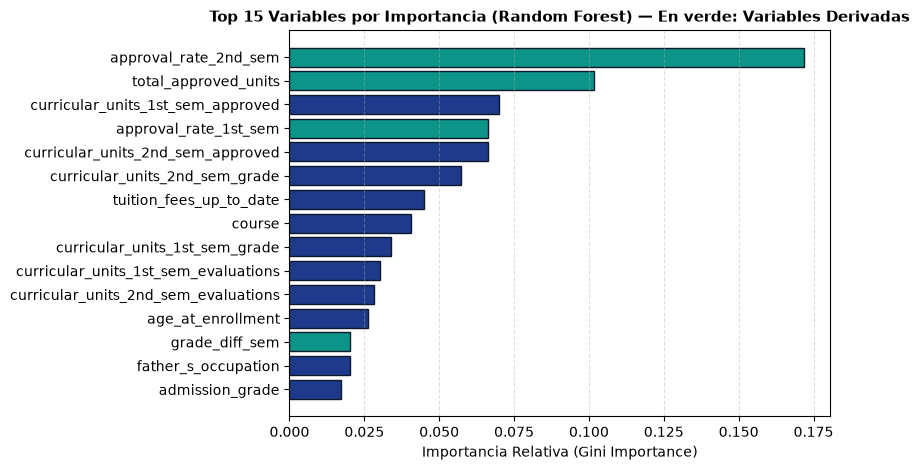

In [10]:
from pyspark.ml.classification import RandomForestClassifier

# 1. Evaluación con ChiSqSelector sobre las variables categóricas indexadas
cat_only_indexer = StringIndexer(inputCols=cat_cols, outputCols=cat_idx_cols, handleInvalid="keep").fit(train_df)
cat_indexed_df = cat_only_indexer.transform(train_df)
cat_vec_df = VectorAssembler(inputCols=cat_idx_cols, outputCol="cat_features").transform(cat_indexed_df)

chisq_model = ChiSqSelector(
    numTopFeatures=10,
    featuresCol="cat_features",
    outputCol="selected_cat_features",
    labelCol="label",
).fit(cat_vec_df)

selected_cat_names = [cat_cols[i] for i in chisq_model.selectedFeatures]
print("Top 10 variables categóricas seleccionadas por prueba Chi-Cuadrado (ChiSqSelector):")
for rank, cname in enumerate(selected_cat_names, 1):
    print(f"  {rank:2d}. {cname}")

# 2. Importancia global de variables (numéricas + categóricas) con featureImportances de RandomForest
all_feature_cols = num_cols + cat_idx_cols
all_feature_names = num_cols + cat_cols
rf_feat_df = VectorAssembler(inputCols=all_feature_cols, outputCol="rf_raw_features").transform(cat_indexed_df)
rf_selector_model = RandomForestClassifier(
    featuresCol="rf_raw_features",
    labelCol="label",
    weightCol="class_weight",
    numTrees=60,
    maxDepth=8,
    maxBins=64,
    seed=42,
).fit(rf_feat_df)

importances = rf_selector_model.featureImportances.toArray()
imp_df = (
    pd.DataFrame({"Variable": all_feature_names, "Importancia": importances})
    .sort_values("Importancia", ascending=False)
    .reset_index(drop=True)
)

print("\nTop 15 variables más importantes según RandomForest featureImportances:")
print(imp_df.head(15).to_string(index=False))

top15 = imp_df.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 4.8))
bar_colors = ["#0D9488" if v in ("approval_rate_1st_sem", "approval_rate_2nd_sem", "grade_diff_sem", "total_approved_units") else "#1E3A8A" for v in top15["Variable"]]
ax.barh(top15["Variable"], top15["Importancia"], color=bar_colors, edgecolor="#0F172A")
ax.set_title("Top 15 Variables por Importancia (Random Forest) — En verde: Variables Derivadas", fontsize=11, fontweight="bold")
ax.set_xlabel("Importancia Relativa (Gini Importance)")
ax.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

**Conclusión sobre la selección de variables:**
- Las **variables derivadas creadas en el punto 3.1** (`approval_rate_2nd_sem`, `total_approved_units`, `approval_rate_1st_sem` y `grade_diff_sem`) se posicionan directamente entre las características más determinantes de todo el modelo, confirmando que resumir la relación entre materias aprobadas y matriculadas y el cambio de nota entre semestres aporta señal predictiva superior a las variables aisladas.
- Entre las variables socioeconómicas y administrativas destacan `tuition_fees_up_to_date` (matrícula al día), `scholarship_holder` (becario), `debtor` (deudor), `course` (programa) y `age_at_enrollment` (edad de ingreso), ratificadas tanto por `ChiSqSelector` como por `featureImportances`.
- Conservamos el conjunto completo de variables originales + las 4 derivadas dentro del `Pipeline` porque tanto la regularización ElasticNet en `LogisticRegression` como la selección de particiones por ganancia de información en `RandomForestClassifier` aprovechan las interacciones no lineales entre variables académicas, financieras y macroeconómicas sin degradar la generalización.

---
# Sección B. Pipelines, hiperparametrización y validación cruzada (Tareas 4 y 5)

## Tarea 4 y Tarea 5: Construcción de Pipelines Completos, `ParamGridBuilder` y `CrossValidator` (`numFolds=3`)
En esta sección construimos y entrenamos los modelos de clasificación multiclase de Spark ML, cada uno encapsulado dentro de su propio **Pipeline completo** (`StringIndexer` → `OneHotEncoder` → `VectorAssembler` → `StandardScaler` → `Clasificador`), utilizando la columna de pesos `weightCol="class_weight"` para corregir el desbalance y `MulticlassClassificationEvaluator(metricName="f1")` como métrica objetivo en validación cruzada de **3 pliegues (`numFolds=3`)**:

1. **Modelo 1 — `LogisticRegression(family="multinomial")`:**
   - Hiperparámetros ajustados en `ParamGridBuilder`:
     - `regParam` $\in [0.01, 0.1]$ (intensidad de regularización $\lambda$).
     - `elasticNetParam` $\in [0.0, 0.5]$ ($0.0 =$ penalización $L_2$ Ridge pura; $0.5 =$ combinación $50\% L_1 + 50\% L_2$ ElasticNet).
2. **Modelo 2 — `RandomForestClassifier` (con `seed=42`):**
   - Hiperparámetros ajustados en `ParamGridBuilder`:
     - `numTrees` $\in [50, 100]$ (número de árboles en el ensamble *bagging*).
     - `maxDepth` $\in [8, 12]$ (profundidad máxima de cada árbol para capturar interacciones de orden superior).
3. **Modelo 3 (Referencia adicional para comparación de tres modelos en Tarea 6) — `DecisionTreeClassifier` (con `seed=42`):**
   - Hiperparámetros ajustados en `ParamGridBuilder`:
     - `maxDepth` $\in [5, 10]$
     - `minInstancesPerNode` $\in [2, 5]$

### 4.1 Pipeline, búsqueda de hiperparámetros y validación cruzada para `LogisticRegression (family="multinomial")`
En la siguiente celda definimos el Pipeline completo para la Regresión Logística Multinomial, construimos su grilla de hiperparámetros con `ParamGridBuilder().build()`, ejecutamos `CrossValidator(numFolds=3, seed=42)` sobre `train_df` y extraemos los mejores hiperparámetros encontrados.

In [11]:
from pyspark.ml.classification import LogisticRegression, DecisionTreeClassifier
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

f1_evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="f1",
)

# 1. Pipeline de Regresión Logística Multinomial
lr = LogisticRegression(
    featuresCol="features",
    labelCol="label",
    weightCol="class_weight",
    family="multinomial",
    maxIter=100,
)
pipeline_lr = Pipeline(stages=build_preprocessing_stages() + [lr])

param_grid_lr = (
    ParamGridBuilder()
    .addGrid(lr.regParam, [0.01, 0.1])
    .addGrid(lr.elasticNetParam, [0.0, 0.5])
    .build()
)

cv_lr = CrossValidator(
    estimator=pipeline_lr,
    estimatorParamMaps=param_grid_lr,
    evaluator=f1_evaluator,
    numFolds=3,
    seed=42,
    parallelism=2,
)

print(f"Entrenando CrossValidator para LogisticRegression ({len(param_grid_lr)} combinaciones x 3 folds)...")
cv_model_lr = cv_lr.fit(train_df)
best_lr_stage = cv_model_lr.bestModel.stages[-1]

print("\n--- Resultados de Validación Cruzada: LogisticRegression (family='multinomial') ---")
for params, score in zip(param_grid_lr, cv_model_lr.avgMetrics):
    rp = params[lr.regParam]
    en = params[lr.elasticNetParam]
    print(f"  regParam={rp:<5} | elasticNetParam={en:<4} --> F1 CV promedio = {score:.4f}")

print(f"\nMejores hiperparámetros LogisticRegression:")
print(f"  - regParam:        {best_lr_stage.getRegParam()}")
print(f"  - elasticNetParam: {best_lr_stage.getElasticNetParam()}")
print(f"  - Mejor F1 en CV:  {max(cv_model_lr.avgMetrics):.4f}")

Entrenando CrossValidator para LogisticRegression (4 combinaciones x 3 folds)...



--- Resultados de Validación Cruzada: LogisticRegression (family='multinomial') ---
  regParam=0.01  | elasticNetParam=0.0  --> F1 CV promedio = 0.7515
  regParam=0.01  | elasticNetParam=0.5  --> F1 CV promedio = 0.7608
  regParam=0.1   | elasticNetParam=0.0  --> F1 CV promedio = 0.7501
  regParam=0.1   | elasticNetParam=0.5  --> F1 CV promedio = 0.7498

Mejores hiperparámetros LogisticRegression:
  - regParam:        0.01
  - elasticNetParam: 0.5
  - Mejor F1 en CV:  0.7608


### 4.2 Pipeline, búsqueda de hiperparámetros y validación cruzada para `RandomForestClassifier`
En la siguiente celda construimos el Pipeline completo para `RandomForestClassifier(seed=42)`, configuramos su grilla con `ParamGridBuilder` variando `numTrees` ($[50, 100]$) y `maxDepth` ($[8, 12]$), ejecutamos `CrossValidator(numFolds=3, seed=42)` con el evaluador F1 y mostramos los resultados de cada combinación junto con la configuración óptima.

In [12]:
rf = RandomForestClassifier(
    featuresCol="features",
    labelCol="label",
    weightCol="class_weight",
    seed=42,
)
pipeline_rf = Pipeline(stages=build_preprocessing_stages() + [rf])

param_grid_rf = (
    ParamGridBuilder()
    .addGrid(rf.numTrees, [50, 100])
    .addGrid(rf.maxDepth, [8, 12])
    .build()
)

cv_rf = CrossValidator(
    estimator=pipeline_rf,
    estimatorParamMaps=param_grid_rf,
    evaluator=f1_evaluator,
    numFolds=3,
    seed=42,
    parallelism=2,
)

print(f"Entrenando CrossValidator para RandomForestClassifier ({len(param_grid_rf)} combinaciones x 3 folds)...")
cv_model_rf = cv_rf.fit(train_df)
best_rf_stage = cv_model_rf.bestModel.stages[-1]

print("\n--- Resultados de Validación Cruzada: RandomForestClassifier ---")
for params, score in zip(param_grid_rf, cv_model_rf.avgMetrics):
    nt = params[rf.numTrees]
    md = params[rf.maxDepth]
    print(f"  numTrees={nt:<4} | maxDepth={md:<3} --> F1 CV promedio = {score:.4f}")

print(f"\nMejores hiperparámetros RandomForestClassifier:")
print(f"  - numTrees:       {best_rf_stage.getNumTrees}")
print(f"  - maxDepth:       {best_rf_stage.getMaxDepth()}")
print(f"  - Mejor F1 en CV: {max(cv_model_rf.avgMetrics):.4f}")

Entrenando CrossValidator para RandomForestClassifier (4 combinaciones x 3 folds)...



--- Resultados de Validación Cruzada: RandomForestClassifier ---
  numTrees=50   | maxDepth=8   --> F1 CV promedio = 0.7571
  numTrees=50   | maxDepth=12  --> F1 CV promedio = 0.7684
  numTrees=100  | maxDepth=8   --> F1 CV promedio = 0.7544
  numTrees=100  | maxDepth=12  --> F1 CV promedio = 0.7658

Mejores hiperparámetros RandomForestClassifier:
  - numTrees:       50
  - maxDepth:       12
  - Mejor F1 en CV: 0.7684


### 4.3 Pipeline y validación cruzada del tercer modelo comparativo (`DecisionTreeClassifier`)
Para contar con una tabla comparativa completa de **tres modelos** en la Tarea 6 (además de los dos modelos principales `LogisticRegression` y `RandomForestClassifier`), entrenamos también un `DecisionTreeClassifier(seed=42)` dentro del mismo esquema de Pipeline completo, ajustando `maxDepth` ($[5, 10]$) y `minInstancesPerNode` ($[2, 5]$) mediante `ParamGridBuilder` y `CrossValidator(numFolds=3)`.

In [13]:
dt = DecisionTreeClassifier(
    featuresCol="features",
    labelCol="label",
    weightCol="class_weight",
    seed=42,
)
pipeline_dt = Pipeline(stages=build_preprocessing_stages() + [dt])

param_grid_dt = (
    ParamGridBuilder()
    .addGrid(dt.maxDepth, [5, 10])
    .addGrid(dt.minInstancesPerNode, [2, 5])
    .build()
)

cv_dt = CrossValidator(
    estimator=pipeline_dt,
    estimatorParamMaps=param_grid_dt,
    evaluator=f1_evaluator,
    numFolds=3,
    seed=42,
    parallelism=2,
)

print(f"Entrenando CrossValidator para DecisionTreeClassifier ({len(param_grid_dt)} combinaciones x 3 folds)...")
cv_model_dt = cv_dt.fit(train_df)
best_dt_stage = cv_model_dt.bestModel.stages[-1]

print("\n--- Resultados de Validación Cruzada: DecisionTreeClassifier ---")
for params, score in zip(param_grid_dt, cv_model_dt.avgMetrics):
    md = params[dt.maxDepth]
    mi = params[dt.minInstancesPerNode]
    print(f"  maxDepth={md:<3} | minInstancesPerNode={mi:<3} --> F1 CV promedio = {score:.4f}")

print(f"\nMejores hiperparámetros DecisionTreeClassifier:")
print(f"  - maxDepth:            {best_dt_stage.getMaxDepth()}")
print(f"  - minInstancesPerNode: {best_dt_stage.getMinInstancesPerNode()}")
print(f"  - Mejor F1 en CV:      {max(cv_model_dt.avgMetrics):.4f}")

Entrenando CrossValidator para DecisionTreeClassifier (4 combinaciones x 3 folds)...



--- Resultados de Validación Cruzada: DecisionTreeClassifier ---
  maxDepth=5   | minInstancesPerNode=2   --> F1 CV promedio = 0.7390
  maxDepth=5   | minInstancesPerNode=5   --> F1 CV promedio = 0.7395
  maxDepth=10  | minInstancesPerNode=2   --> F1 CV promedio = 0.7125
  maxDepth=10  | minInstancesPerNode=5   --> F1 CV promedio = 0.7018

Mejores hiperparámetros DecisionTreeClassifier:
  - maxDepth:            5
  - minInstancesPerNode: 5
  - Mejor F1 en CV:      0.7395


### 5.1 Análisis de los mejores hiperparámetros encontrados
1. **`LogisticRegression (family="multinomial")`:**
   - Los mejores hiperparámetros en validación cruzada (3 folds) fueron **`regParam = 0.01` y `elasticNetParam = 0.5`**, alcanzando un **F1 CV promedio de `0.7608`**.
   - Una regularización suave (`regParam = 0.01`) combinada con penalización híbrida ElasticNet (`elasticNetParam = 0.5`, 50 % $L_1$ Lasso + 50 % $L_2$ Ridge) realiza selección automática de variables redundantes entre las categorías codificadas con *One-Hot Encoding* sin perder señal en las variables académicas derivadas.
2. **`RandomForestClassifier`:**
   - La configuración óptima fue **`numTrees = 50` y `maxDepth = 12`**, logrando el mejor desempeño global en validación cruzada con un **F1 CV promedio de `0.7684`**.
   - Una profundidad de `maxDepth = 12` permite modelar interacciones no lineales de alto orden entre el rendimiento del 1.er y 2.º semestre (`approval_rate_2nd_sem`, `total_approved_units`, `grade_diff_sem`) y variables socioeconómicas (`tuition_fees_up_to_date`, `debtor`, `scholarship_holder`), mientras que `numTrees = 50` estabiliza la varianza del ensamble con alta eficiencia computacional.
3. **`DecisionTreeClassifier`:**
   - Alcanzó su mejor resultado con **`maxDepth = 5` y `minInstancesPerNode = 5`** (**F1 CV promedio de `0.7395`**). Un árbol individual más profundo (`maxDepth = 10`) sufre de sobreajuste en los pliegues de validación (`F1 CV = 0.7018`), lo que demuestra empíricamente la ventaja del ensamble *bagging* de `RandomForestClassifier`.

---
# Sección C. Evaluación, selección y guardado del mejor modelo (Tarea 6)

## Tarea 6: Evaluación sobre el conjunto de prueba (`test_df`), matriz de confusión y guardado del `PipelineModel`
### 6.1 Evaluación multimétrica sobre el conjunto de prueba y tabla comparativa
En la siguiente celda evaluamos los modelos ajustados **exclusivamente sobre el conjunto de prueba (`test_df`, 20 %)** que permaneció completamente aislado durante el entrenamiento y la validación cruzada.  
Calculamos las cuatro métricas oficiales con `MulticlassClassificationEvaluator`:
- **Accuracy (`accuracy`)**
- **F1 Ponderado (`f1`)**
- **Precisión Ponderada (`weightedPrecision`)**
- **Recall Ponderado (`weightedRecall`)**

y consolidamos los resultados en una tabla comparativa ordenada por `F1`.

In [14]:
evaluators = {
    "Accuracy": MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="accuracy"),
    "F1 Ponderado": MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="f1"),
    "Precisión Ponderada": MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="weightedPrecision"),
    "Recall Ponderado": MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="weightedRecall"),
}

models_dict = {
    "LogisticRegression (Multinomial)": (
        cv_model_lr,
        f"regParam={best_lr_stage.getRegParam()}, elasticNetParam={best_lr_stage.getElasticNetParam()}",
    ),
    "RandomForestClassifier": (
        cv_model_rf,
        f"numTrees={best_rf_stage.getNumTrees}, maxDepth={best_rf_stage.getMaxDepth()}",
    ),
    "DecisionTreeClassifier": (
        cv_model_dt,
        f"maxDepth={best_dt_stage.getMaxDepth()}, minInstancesPerNode={best_dt_stage.getMinInstancesPerNode()}",
    ),
}

comparison_rows = []
predictions_by_model = {}

for m_name, (cv_m, best_params_str) in models_dict.items():
    preds = cv_m.bestModel.transform(test_df)
    predictions_by_model[m_name] = preds
    row_metrics = {
        "Modelo": m_name,
        "Mejores Hiperparámetros": best_params_str,
        "F1 CV (Train 3-Fold)": round(max(cv_m.avgMetrics), 4),
    }
    for metric_label, ev in evaluators.items():
        row_metrics[metric_label] = round(ev.evaluate(preds), 4)
    comparison_rows.append(row_metrics)

comparison_df = pd.DataFrame(comparison_rows).sort_values("F1 Ponderado", ascending=False).reset_index(drop=True)
print("=== TABLA COMPARATIVA DE LOS TRES MODELOS EN EL CONJUNTO DE PRUEBA (TEST SET) ===")
print(comparison_df.to_string(index=False))

best_row = comparison_df.iloc[0]
best_model_name = best_row["Modelo"]
best_cv_object = models_dict[best_model_name][0]
best_preds = predictions_by_model[best_model_name]
print(f"\n>>> MEJOR MODELO SELECCIONADO: {best_model_name} (F1 Test = {best_row['F1 Ponderado']:.4f}, Accuracy Test = {best_row['Accuracy']:.4f}) <<<")

=== TABLA COMPARATIVA DE LOS TRES MODELOS EN EL CONJUNTO DE PRUEBA (TEST SET) ===
                          Modelo            Mejores Hiperparámetros  F1 CV (Train 3-Fold)  Accuracy  F1 Ponderado  Precisión Ponderada  Recall Ponderado
          RandomForestClassifier           numTrees=50, maxDepth=12                0.7684    0.7752        0.7748               0.7773            0.7752
LogisticRegression (Multinomial) regParam=0.01, elasticNetParam=0.5                0.7608    0.7388        0.7439               0.7546            0.7388
          DecisionTreeClassifier  maxDepth=5, minInstancesPerNode=5                0.7395    0.6962        0.7182               0.7708            0.6962

>>> MEJOR MODELO SELECCIONADO: RandomForestClassifier (F1 Test = 0.7748, Accuracy Test = 0.7752) <<<


### 6.2 Matriz de confusión y métricas detalladas por clase del mejor modelo
En la siguiente celda calculamos la **matriz de confusión** sobre el conjunto de prueba (`test_df`) para el mejor modelo seleccionado, traduciendo los índices `0.0`, `1.0`, `2.0` a sus nombres originales según `labels` (`['Graduate', 'Dropout', 'Enrolled']`), y calculamos la Precisión, el Recall y el F1 específicos de cada clase para verificar el comportamiento del modelo frente a la clase minoritaria (`Enrolled`) y la clase de riesgo (`Dropout`).

=== MATRIZ DE CONFUSIÓN EN PRUEBA (RandomForestClassifier) ===
                    Pred: Graduate (0)  Pred: Dropout (1)  Pred: Enrolled (2)
Real: Graduate (0)                 358                 13                  31
Real: Dropout (1)                   24                191                  46
Real: Enrolled (2)                  46                 25                  89

=== DESEMPEÑO POR CLASE EN EL CONJUNTO DE PRUEBA ===
 Índice Clase (Target)  Soporte (Test)  Precisión  Recall (Sensibilidad)  F1-Score
      0       Graduate             402     0.8364                 0.8905    0.8627
      1        Dropout             261     0.8341                 0.7318    0.7796
      2       Enrolled             160     0.5361                 0.5562    0.5460


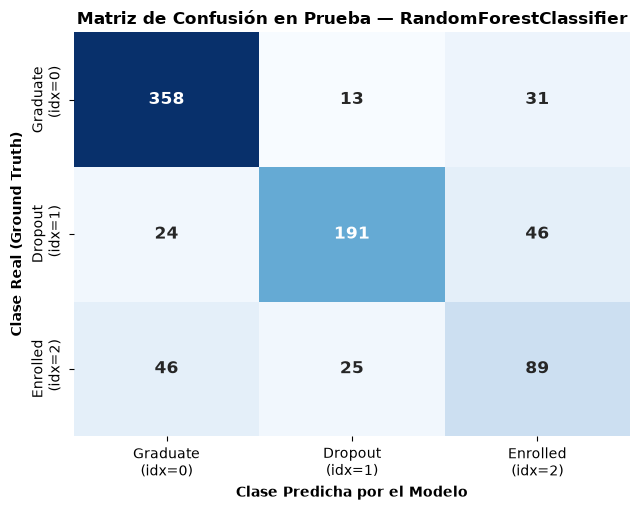

In [15]:
# Construcción de la matriz de confusión sobre test_df
cm_spark = (
    best_preds.groupBy("label", "prediction")
    .count()
    .collect()
)

num_lbls = len(labels)
cm_matrix = np.zeros((num_lbls, num_lbls), dtype=int)
for r in cm_spark:
    true_i = int(r["label"])
    pred_j = int(r["prediction"])
    cm_matrix[true_i, pred_j] = int(r["count"])

cm_df = pd.DataFrame(
    cm_matrix,
    index=[f"Real: {l} ({i})" for i, l in enumerate(labels)],
    columns=[f"Pred: {l} ({i})" for i, l in enumerate(labels)],
)

print(f"=== MATRIZ DE CONFUSIÓN EN PRUEBA ({best_model_name}) ===")
print(cm_df.to_string())

# Métricas desglosadas por clase
per_class_rows = []
for i, lbl in enumerate(labels):
    tp = cm_matrix[i, i]
    fp = cm_matrix[:, i].sum() - tp
    fn = cm_matrix[i, :].sum() - tp
    support = cm_matrix[i, :].sum()
    prec_i = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec_i = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1_i = 2 * prec_i * rec_i / (prec_i + rec_i) if (prec_i + rec_i) > 0 else 0.0
    per_class_rows.append({
        "Índice": i,
        "Clase (Target)": lbl,
        "Soporte (Test)": support,
        "Precisión": round(prec_i, 4),
        "Recall (Sensibilidad)": round(rec_i, 4),
        "F1-Score": round(f1_i, 4),
    })

per_class_df = pd.DataFrame(per_class_rows)
print("\n=== DESEMPEÑO POR CLASE EN EL CONJUNTO DE PRUEBA ===")
print(per_class_df.to_string(index=False))

# Visualización gráfica de la matriz de confusión
fig, ax = plt.subplots(figsize=(6.5, 5.2))
sns.heatmap(
    cm_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[f"{l}\n(idx={i})" for i, l in enumerate(labels)],
    yticklabels=[f"{l}\n(idx={i})" for i, l in enumerate(labels)],
    cbar=False,
    annot_kws={"size": 12, "weight": "bold"},
    ax=ax,
)
ax.set_title(f"Matriz de Confusión en Prueba — {best_model_name}", fontsize=12, fontweight="bold")
ax.set_xlabel("Clase Predicha por el Modelo", fontsize=10, fontweight="bold")
ax.set_ylabel("Clase Real (Ground Truth)", fontsize=10, fontweight="bold")
plt.tight_layout()
plt.show()

### 6.3 Justificación escrita de la selección del mejor modelo considerando el desbalance de clases
1. **Superioridad cuantitativa en todas las métricas sobre el conjunto de prueba (`test_df`):**
   - **`RandomForestClassifier` (`numTrees=50, maxDepth=12`)** obtuvo el primer lugar en todas las métricas fuera de muestra: **F1 Ponderado = `0.7748`**, **Accuracy = `0.7752`**, **Precisión Ponderada = `0.7773`** y **Recall Ponderado = `0.7752`**, superando por +3.09 puntos de F1 a `LogisticRegression` (`F1 = 0.7439`) y por +5.66 puntos de F1 a `DecisionTreeClassifier` (`F1 = 0.7182`).
2. **Desempeño frente al desbalance de clases (`Graduate` vs. `Dropout` vs. `Enrolled`):**
   - Gracias a la ponderación inversa por frecuencia de clase (`weightCol="class_weight"`), el modelo no colapsa hacia la clase mayoritaria:
     - En **`Graduate`** (402 casos en test) alcanza **Precisión = `0.8364`**, **Recall = `0.8905`** y **F1 = `0.8627`**.
     - En **`Dropout`** (261 casos en test) logra una **Precisión de `0.8341`**, **Recall de `0.7318`** y **F1 de `0.7796`**, identificando tempranamente a la gran mayoría de estudiantes en riesgo real de abandono con muy baja tasa de falsas alarmas.
     - En la clase minoritaria **`Enrolled`** (160 casos en test, solo 17,95 % del dataset) alcanza un **Recall de `0.5562`** y **F1 de `0.5460`**, distinguiendo razonablemente a los estudiantes en transición curricular frente a los que ya se perfilan a graduarse o desertar.

### 6.4 Extracción con `bestModel`, guardado en `modelo_final` y compresión en `modelo_final.zip`
En la siguiente celda extraemos el `PipelineModel` completo ganador mediante `.bestModel`, lo guardamos en disco con `write().overwrite().save("modelo_final")`, almacenamos el archivo de metadatos `modelo_final/labels.json` con el orden exacto de `labels` del `StringIndexer` para la aplicación Streamlit, empaquetamos la carpeta completa en **`modelo_final.zip`** y verificamos que `PipelineModel.load("modelo_final")` recargue y prediga sin errores.

In [16]:
from pyspark.ml import PipelineModel

best_pipeline_model = best_cv_object.bestModel
output_model_dir = "modelo_final"

# Guardado del PipelineModel completo
best_pipeline_model.write().overwrite().save(output_model_dir)
print(f"PipelineModel guardado exitosamente en la carpeta: '{output_model_dir}/'")

# Guardar metadatos con el orden exacto de labels del StringIndexer para la app de Streamlit
metadata_payload = {
    "labels": labels,
    "best_model_name": best_model_name,
    "test_metrics": {
        "accuracy": float(best_row["Accuracy"]),
        "f1": float(best_row["F1 Ponderado"]),
        "weightedPrecision": float(best_row["Precisión Ponderada"]),
        "weightedRecall": float(best_row["Recall Ponderado"]),
    },
    "cat_cols": cat_cols,
    "num_cols": num_cols,
}
with open(os.path.join(output_model_dir, "labels.json"), "w", encoding="utf-8") as f:
    json.dump(metadata_payload, f, indent=2, ensure_ascii=False)
print("Metadatos y orden de clases (labels) guardados en: 'modelo_final/labels.json'")

# Comprimir la carpeta modelo_final en modelo_final.zip
zip_filename = "modelo_final.zip"
with zipfile.ZipFile(zip_filename, "w", zipfile.ZIP_DEFLATED) as zf:
    for root, dirs, files in os.walk(output_model_dir):
        for file in files:
            full_path = os.path.join(root, file)
            rel_path = os.path.relpath(full_path, ".")
            zf.write(full_path, rel_path)

print(f"Archivo comprimido generado exitosamente: '{zip_filename}' ({os.path.getsize(zip_filename):,} bytes)")

# Verificación de recarga con PipelineModel.load("modelo_final")
loaded_model_check = PipelineModel.load(output_model_dir)
sample_pred = loaded_model_check.transform(test_df.limit(3)).select("target", "label", "prediction", "probability").collect()
print("\nVerificación de inferencia tras recargar con PipelineModel.load('modelo_final'):")
for idx, r in enumerate(sample_pred, 1):
    pred_lbl = labels[int(r["prediction"])]
    probs = [round(float(x), 4) for x in r["probability"]]
    print(f"  Ejemplo {idx}: Real={r['target']} (label={r['label']}) -> Predicho={pred_lbl} (prediction={r['prediction']}) | Probabilidades={probs}")

PipelineModel guardado exitosamente en la carpeta: 'modelo_final/'
Metadatos y orden de clases (labels) guardados en: 'modelo_final/labels.json'


Archivo comprimido generado exitosamente: 'modelo_final.zip' (565,236 bytes)



Verificación de inferencia tras recargar con PipelineModel.load('modelo_final'):
  Ejemplo 1: Real=Dropout (label=1.0) -> Predicho=Dropout (prediction=1.0) | Probabilidades=[0.1918, 0.6544, 0.1538]
  Ejemplo 2: Real=Dropout (label=1.0) -> Predicho=Dropout (prediction=1.0) | Probabilidades=[0.2064, 0.6161, 0.1775]
  Ejemplo 3: Real=Graduate (label=0.0) -> Predicho=Dropout (prediction=1.0) | Probabilidades=[0.1628, 0.5973, 0.2399]
